In [1]:
# Generating SIP signatures 
# Spectral Induced Polarization Signatures 
# char. electrical responses of a material measured over a range of freq

# In ordinary ERT we inject current and measure potential diff which gives us R

# when electric field is applied, it creates charges accumalate at interface within material (polarisation effect)
# this changes with the freq of the applied i
# sip measures freq dep response

In [2]:
# Cole-cole signature 
# interpolating using points on graph (read further joining - using .)

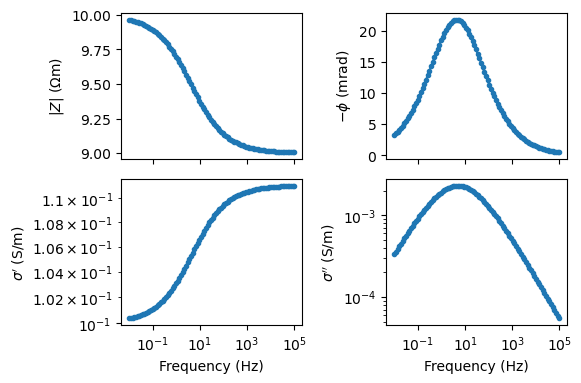

In [3]:
from pygimli.physics.SIP import modelColeColeRho
import numpy as np
import pygimli as pg
import matplotlib as mpl

f = np.logspace(-2, 5, 100)
# logspace with starting value =-2,
# end=5
# no. of spacings = 100
# our freq range is 10^-2 to 10^5

Z = modelColeColeRho(f, rho=10, m=0.1, tau=0.04, c=0.5)
# freq, R, chargeability (m), relaxation time (tau), cole-dispersion exp (c)
# z is an array with 100 values stored - freq response at each diff freq value

fig, axes = pg.plt.subplots(2, 2, #2x2 space for 4 graphs
                            figsize=(15 / 2.54, 10 / 2.54), sharex=True) # converting to inches # all graphs have same x axis (log freq)

ax = axes[0, 0] #1st graph Z vs freq
ax.semilogx(f, np.abs(Z), '.-') #absolute value of z
# .- means show . connected with -
ax.set_ylabel(r'$|Z|$ ($\Omega$m)')

# second graph 
ax = axes[0, 1]
ax.semilogx(f, -np.angle(Z) * 1e3, '.-') #plotting neg phase angle with freq # tan angle of z
ax.set_ylabel(r'$-\phi$ (mrad)')

# third graph 
ax = axes[1, 0]
Y = 1 / Z #conductivity 
ax.loglog(f, np.real(Y), '.-') #real part of z
# in phase conductivity 
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel(r"$\sigma'$ (S$/$m)")

# fourth graph 
ax = axes[1, 1]
ax.loglog(f, np.imag(Y), '.-') #out of phase conductivity comp
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel(r"$\sigma''$ (S$/$m)")

for ax in axes.flat: #present all 4 graphs at once 
    ax.xaxis.set_major_locator(mpl.ticker.LogLocator(numticks=5)) # min 5 ticks to connect and interpolate 
fig.tight_layout()

In [4]:
# double cole-cole signature 
# the idea is that 1 geological structure can generate different polarization mech operating over diff freq ranges 
# graph is drawn based on which polarization mech. is more predominant at that point 

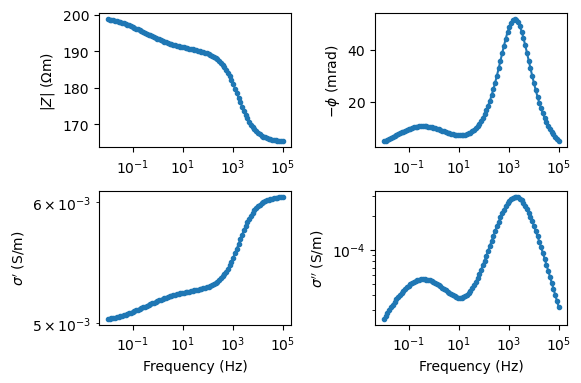

In [5]:
from pygimli.physics.SIP import modelColeColeRho
import numpy as np
import pygimli as pg

f = np.logspace(-2, 5, 100)

# term1
Z1 = modelColeColeRho(f, rho=1, m=0.1, tau=0.5, c=0.5)
# term2
Z2 = modelColeColeRho(f, rho=1, m=0.25, tau=0.0001, c=0.8)
# create sum
rho0 = 100 #overall scaling factor
Z = rho0 * (Z1 + Z2)

fig, axes = pg.plt.subplots(2, 2, figsize=(15 / 2.54, 10 / 2.54))

ax = axes[0, 0]
ax.semilogx(f, np.abs(Z), '.-')
ax.set_ylabel(r'$|Z|$ ($\Omega$m)')
ax = axes[0, 1]
ax.semilogx(f, -np.angle(Z) * 1e3, '.-')
ax.set_ylabel(r'$-\phi$ (mrad)')
ax = axes[1, 0]
Y = 1 / Z
ax.loglog(f, np.real(Y), '.-')
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel(r"$\sigma'$ (S$/$m)")
ax = axes[1, 1]
ax.loglog(f, np.imag(Y), '.-')
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel(r"$\sigma''$ (S$/$m)")

for ax in axes.flat:
    ax.xaxis.set_major_locator(
        mpl.ticker.LogLocator(numticks=5)
    )
fig.tight_layout()